# Laboratório: higiene de corpus

A resposta do laboratório anterior foi contada num corpus sujo. Aqui cada defeito ganha uma
técnica, e no fim a resposta é refeita:

| defeito na resposta | técnica |
|---|---|
| a mesma avaliação em vários pedidos | deduplicação exata (`review_id`) |
| "não recebi" e "nao recebi" separados | normalização |
| mensagens sem conteúdo | filtragem heurística |
| a mesma frase com pequenas variações | matching: Jaccard de trigramas, para deduplicar e para agrupar |
| telefone e link de cliente no texto | anonimização (regex de dados pessoais) |

## 0. Preparação

O notebook roda no **Google Colab** ou no seu computador. A primeira célula instala as bibliotecas
que faltam (rode uma vez); a de dados baixa as avaliações da Olist direto do Kaggle com `curl`, sem
conta. Se o download falhar, baixe o zip pelo navegador em
`kaggle.com/datasets/olistbr/brazilian-ecommerce` e extraia `olist_order_reviews_dataset.csv` na
pasta `dados_olist/`.

In [1]:
# Instala o que falta (no Colab já vem quase tudo; no seu computador, rode uma vez)
%pip install -q pandas numpy matplotlib nltk

import nltk
nltk.download("stopwords", quiet=True)   # a lista de stopwords em português, para a resposta no fim


Note: you may need to restart the kernel to use updated packages.


True

In [2]:
import re
import unicodedata
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

GRAY, RED, INDIGO, GREEN, LIGHT = "#64748b", "#ef4444", "#6366f1", "#22c55e", "#cbd5e1"
plt.rcParams.update({"figure.figsize": (9, 3.2), "font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False})


def br(valor, casas=0):
    # 40.977 e 14,0: milhar com ponto, decimal com vírgula
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


In [3]:
URL = "https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce"
PASTA = Path("dados_olist")  # Altere para o caminho do seu sistema, se já tiver os CSV
CAMINHO = PASTA / "olist_order_reviews_dataset.csv"

if not CAMINHO.exists():  # baixa o zip do Kaggle (cerca de 45 MB) e extrai só as avaliações
    PASTA.mkdir(parents=True, exist_ok=True)
    print("baixando do Kaggle...")
    !curl -L --fail -sS -o {PASTA}/olist.zip {URL}
    with zipfile.ZipFile(PASTA / "olist.zip") as arquivo:
        arquivo.extract(CAMINHO.name, PASTA)

bruto = pd.read_csv(CAMINHO, dtype=object)
avaliacoes = pd.DataFrame({"review_id": bruto["review_id"], "nota": bruto["review_score"].astype(int),
                           "mensagem": bruto["review_comment_message"],
                           "data": pd.to_datetime(bruto["review_creation_date"])})
mensagens = avaliacoes.dropna(subset=["mensagem"]).reset_index(drop=True)
mensagens["grupo"] = np.select([mensagens["nota"] <= 2, mensagens["nota"] == 3], ["ruim", "neutra"], "boa")
print(f"{br(len(avaliacoes))} avaliações; {br(len(mensagens))} com comentário")
mensagens["grupo"].value_counts()


99.224 avaliações; 40.977 com comentário


grupo
boa       26530
ruim      10890
neutra     3557
Name: count, dtype: int64

In [4]:
def grafico_ruins_boas(rotulos, ruins, boas, titulo, antes=None):
    # barras horizontais: % das avaliações ruins (vermelho) e das boas (cinza), como nos slides
    rotulos, ruins, boas = list(rotulos), list(ruins), list(boas)
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(rotulos) + 1.2))
    y = np.arange(len(rotulos))[::-1]
    ax.barh(y + 0.18, ruins, height=0.36, color=RED, label="ruins (notas 1 e 2)")
    ax.barh(y - 0.18, boas, height=0.36, color=LIGHT, label="boas (notas 4 e 5)")
    if antes is not None:
        ax.scatter(list(antes), y + 0.18, marker="|", s=400, color="black", label="ruins, antes da higiene")
    for yi, v in zip(y, ruins):
        ax.text(v + 0.3, yi + 0.18, br(v, 1) + "%", va="center", fontsize=11)
    ax.set_yticks(y, rotulos)
    ax.set_xlabel("% das avaliações")
    ax.set_title(titulo)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()


In [5]:
COMPOSTO = (r"https?://\S+|www\.\S+"                      # URL
            r"|R\$\s?\d+(?:[.,]\d+)*"                     # dinheiro
            r"|\d+(?:[.,]\d+)*%?"                         # número
            r"|[^\W\d_]+(?:[-'’][^\W\d_]+)*"              # palavra, com hífen ou apóstrofo
            r"|[\U0001F300-\U0001FAFF☀-➿][\U0001F3FB-\U0001F3FF]?")  # emoji com tom de pele


def tokenizar(texto):
    return re.findall(COMPOSTO, texto)


## 1. Deduplicação exata

O mesmo `review_id` aparece ligado a mais de um pedido. Uma pessoa, uma opinião: fica uma linha.

In [6]:
# quantas linhas repetem um review_id já visto
repetidas = mensagens["review_id"].duplicated()
print(f"{br(repetidas.sum())} linhas a mais")
# uma linha por review_id
base = mensagens.drop_duplicates("review_id").reset_index(drop=True)

len(base)


309 linhas a mais


40668

## 2. Unicode: o mesmo caractere, mais de uma grafia

"é" pode ser um ponto de código (U+00E9) ou dois, "e" + acento (U+0065 U+0301): na tela iguais,
para o computador diferentes. "ª" (U+00AA) parece um "a", mas é outro caractere. **NFKC** é uma
regra do Unicode que escolhe uma grafia só: **C**, composição (letra + acento viram um caractere);
**K**, compatibilidade (a variante vira a letra comum: ª → a, º → o).

In [7]:
def pontos(texto):
    # cada caractere como U+XXXX: ord dá o número do ponto de código; :04X o escreve em hexadecimal
    return " ".join(f"U+{ord(ch):04X}" for ch in texto)


pronto, partes = "é", "é"
# as duas grafias de é: na tela iguais, mas == compara os pontos de código
print(pronto, partes, "iguais?", pronto == partes)
# os pontos de código de cada uma: um só (é pronto) contra dois (e + acento)
print(pontos(pronto), "·", pontos(partes))

# depois do NFKC, as duas viram a mesma
print("iguais depois do NFKC?", unicodedata.normalize("NFKC", partes) == pronto)
# e a variante ª vira a letra comum
print("1ª →", unicodedata.normalize("NFKC", "1ª"))

# quantas mensagens da Olist mudam com NFKC
muda = mensagens["mensagem"].map(lambda t: unicodedata.normalize("NFKC", t) != t)
print(muda.sum(), "mensagens mudam com NFKC")


é é iguais? False
U+00E9 · U+0065 U+0301
iguais depois do NFKC? True
1ª → 1a
43 mensagens mudam com NFKC


## 3. Normalização, passo a passo

Normalizar é escolher uma grafia só para o que é o mesmo texto. Cinco passos, em ordem; os três
últimos são decisões: perdem informação (o acento de "é", o emoji).

In [8]:
def normalizar(texto, passos=("strip", "espacos", "nfkc", "minusculas", "sem_acento", "sem_simbolos")):
    for passo in passos:
        if passo == "strip":
            texto = texto.strip()
        elif passo == "espacos":
            texto = re.sub(r"\s+", " ", texto)               # quebras de linha e espaços repetidos
        elif passo == "nfkc":
            texto = unicodedata.normalize("NFKC", texto)     # grafia única: "1ª" vira "1a"; e + acento vira é
        elif passo == "minusculas":
            texto = texto.casefold()
        elif passo == "sem_acento":                          # separa letra e acento (NFD) e tira o acento
            texto = "".join(ch for ch in unicodedata.normalize("NFD", texto) if unicodedata.category(ch) != "Mn")
        elif passo == "sem_simbolos":
            texto = re.sub(r"\s+", " ", re.sub(r"[^\w\s.,!?;:$%/'’-]", " ", texto)).strip()  # emojis e símbolos
    return texto


PASSOS = ["strip", "espacos", "nfkc", "minusculas", "sem_acento", "sem_simbolos"]


In [9]:
for texto in ["AINDA NÃO RECEBI O PRODUTO ", "Ótimo 👍🏼 ", "De 1ª qualidade!!!!"]:
    print(repr(texto))
    for passo in PASSOS:
        # aplique o próximo passo ao resultado do anterior
        texto = normalizar(texto, [passo])
        print(f"  {passo:<13}", repr(texto))


'AINDA NÃO RECEBI O PRODUTO '
  strip         'AINDA NÃO RECEBI O PRODUTO'
  espacos       'AINDA NÃO RECEBI O PRODUTO'
  nfkc          'AINDA NÃO RECEBI O PRODUTO'
  minusculas    'ainda não recebi o produto'
  sem_acento    'ainda nao recebi o produto'
  sem_simbolos  'ainda nao recebi o produto'
'Ótimo 👍🏼 '
  strip         'Ótimo 👍🏼'
  espacos       'Ótimo 👍🏼'
  nfkc          'Ótimo 👍🏼'
  minusculas    'ótimo 👍🏼'
  sem_acento    'otimo 👍🏼'
  sem_simbolos  'otimo'
'De 1ª qualidade!!!!'
  strip         'De 1ª qualidade!!!!'
  espacos       'De 1ª qualidade!!!!'
  nfkc          'De 1a qualidade!!!!'
  minusculas    'de 1a qualidade!!!!'
  sem_acento    'de 1a qualidade!!!!'
  sem_simbolos  'de 1a qualidade!!!!'


Cada passo troca ou tira pontos de código:

In [10]:
for passo, antes in [("espacos", ".\r\nP"), ("nfkc", "1ª"), ("nfkc", "é"), ("minusculas", "NÃO"),
                     ("sem_acento", "ã"), ("sem_simbolos", "👍🏼")]:
    # aplique só esse passo
    depois = normalizar(antes, [passo])
    # os pontos de código antes e depois
    print(passo, "·", pontos(antes), "→", pontos(depois))


espacos · U+002E U+000D U+000A U+0050 → U+002E U+0020 U+0050
nfkc · U+0031 U+00AA → U+0031 U+0061
nfkc · U+0065 U+0301 → U+00E9
minusculas · U+004E U+00C3 U+004F → U+006E U+00E3 U+006F
sem_acento · U+00E3 → U+0061
sem_simbolos · U+1F44D U+1F3FC → 


O efeito no corpus: depois de cada passo, quantas mensagens repetidas e quantos tokens únicos.

In [11]:
for i, nome in enumerate(["bruto"] + PASSOS):
    # o texto com os i primeiros passos (i = 0: o bruto)
    norm = base["mensagem"].map(lambda t: normalizar(t, PASSOS[:i]))
    # o vocabulário: os tokens únicos do corpus
    vocab = {tok for t in norm for tok in tokenizar(t)}
    print(f"{nome:<13} repetidas={br(norm.duplicated().sum()):>6}  tokens únicos={br(len(vocab)):>7}")

# a coluna normalizada com todos os passos, usada daqui em diante
base["norm"] = base["mensagem"].map(normalizar)


bruto         repetidas= 4.509  tokens únicos= 20.291


strip         repetidas= 5.051  tokens únicos= 20.291


espacos       repetidas= 5.052  tokens únicos= 20.291


nfkc          repetidas= 5.052  tokens únicos= 20.286


minusculas    repetidas= 5.669  tokens únicos= 15.810


sem_acento    repetidas= 5.804  tokens únicos= 15.081


sem_simbolos  repetidas= 5.842  tokens únicos= 15.002


In [12]:
# quantas avaliações viram "muito bom" depois de normalizar
print("'muito bom' depois de normalizar:", (base["norm"] == "muito bom").sum(), "avaliações")
# quantas grafias originais diferentes elas tinham
print("grafias diferentes:", base.loc[base["norm"] == "muito bom", "mensagem"].nunique())


'muito bom' depois de normalizar: 468 avaliações
grafias diferentes: 13


## 4. Filtragem heurística

Cinco regras simples, como colunas booleanas. Só "sem nenhuma letra" remove; as outras marcam
para revisão, porque também pegam elogios legítimos ("Ótimo", "OK RECOMENDO").

In [13]:
leve = base["mensagem"].map(lambda t: normalizar(t, ["strip", "espacos", "nfkc"]))

def caixa_alta(t):
    # só as letras: espaços, números, pontuação e emojis ficam fora da conta
    letras = [ch for ch in t if ch.isalpha()]
    # texto com 8 letras ou mais (um "OK" não conta) e mais de 60% delas maiúsculas
    return len(letras) >= 8 and sum(ch.isupper() for ch in letras) / len(letras) > 0.6

regras = pd.DataFrame({
    # [^\W\d_] é "letra": nem não-palavra (\W), nem dígito (\d), nem _. O ~ inverte: nenhuma letra
    "sem nenhuma letra": ~leve.str.contains(r"[^\W\d_]", regex=True),
    # o texto inteiro tem até 2 tokens ("Ótimo", "muito bom")
    "até 2 tokens": leve.map(lambda t: len(tokenizar(t)) <= 2),
    "mais de 60% em caixa alta": leve.map(caixa_alta),
    # uma letra capturada pelos parênteses, seguida dela mesma (\1) 3 vezes ou mais: "muiiiito"
    "letra repetida 4 vezes": leve.map(lambda t: re.search(r"([^\W\d_])\1{3,}", t) is not None),
    # "??" é o que sobrou de emojis que se perderam na exportação do arquivo
    "?? no lugar de emoji": leve.str.contains("??", regex=False),
})
# marcada por pelo menos uma regra
marcadas = regras.any(axis=1)
# quantas das marcadas são elogios (nota 5)
print(f"{br(100 * (base.loc[marcadas, 'nota'] == 5).mean(), 1)}% das marcadas têm nota 5")
regras.sum()


64,7% das marcadas têm nota 5


sem nenhuma letra             186
até 2 tokens                 5641
mais de 60% em caixa alta    1279
letra repetida 4 vezes        135
?? no lugar de emoji          124
dtype: int64

In [14]:
# remova só as mensagens sem nenhuma letra
final = base[~regras["sem nenhuma letra"]].reset_index(drop=True)

print(f"saem {br(len(mensagens) - len(final))} mensagens: ficam {br(len(final))}")


saem 495 mensagens: ficam 40.482


## 5. Trigramas, passo a passo

**Matching** é decidir se dois textos dizem a mesma coisa, com uma **similaridade** de 0 a 1 e
um limiar: alto, acha duplicatas; mais baixo, agrupa textos parecidos. Para isso, cada texto vira
o conjunto dos seus **trigramas**, 3 tokens seguidos (em inglês, *shingles*):

1. tokenize o texto: `toks`;
2. pegue a janela de 3 tokens que começa na posição i: `toks[i:i + 3]`;
3. junte os 3 com espaço: um trigrama;
4. ande uma posição e repita, até a última janela que ainda tem 3 tokens.

| i | `toks[i:i + 3]` | trigrama |
|---|---|---|
| 0 | o, produto, chegou | o produto chegou |
| 1 | produto, chegou, antes | produto chegou antes |
| 2 | chegou, antes, do | chegou antes do |
| 3 | antes, do, prazo | antes do prazo |

Com 6 tokens, i vai de 0 a 3: `range(len(toks) - 2)`.

In [15]:
toks = tokenizar(normalizar("o produto chegou antes do prazo."))
print(toks)
for i in range(len(toks) - 2):
    # a janela da posição i e o trigrama: os 3 tokens juntos com espaço
    print(i, toks[i:i + 3], "→", " ".join(toks[i:i + 3]))


['o', 'produto', 'chegou', 'antes', 'do', 'prazo']
0 ['o', 'produto', 'chegou'] → o produto chegou
1 ['produto', 'chegou', 'antes'] → produto chegou antes
2 ['chegou', 'antes', 'do'] → chegou antes do
3 ['antes', 'do', 'prazo'] → antes do prazo


A função faz o mesmo e guarda os trigramas num conjunto. Um texto com menos de 3 tokens
("muito bom") vira um trigrama só, ele inteiro.

In [16]:
def trigramas(texto, k=3):
    toks = tokenizar(texto)
    # quantas janelas cabem no texto (pelo menos 1, para texto curto)
    n_janelas = max(1, len(toks) - k + 1)
    # o conjunto dos trigramas: cada janela juntada com espaço
    return {" ".join(toks[i:i + k]) for i in range(n_janelas)}


print(trigramas("o produto chegou antes do prazo"))
print(trigramas("muito bom"))


{'o produto chegou', 'chegou antes do', 'antes do prazo', 'produto chegou antes'}
{'muito bom'}


## 6. Similaridade de Jaccard

Num diagrama de Venn, a interseção é o que está nos dois conjuntos e a união o que está em pelo
menos um:

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

$|\cdot|$ conta os elementos; $J$ vai de 0 (nada em comum) a 1 (iguais).

In [17]:
def jaccard(a, b):
    # interseção dividida pela união
    return len(a & b) / len(a | b)


A = trigramas(normalizar("o produto chegou antes do prazo."))
B = trigramas(normalizar("otimo produto, chegou antes do prazo."))
print("só em A:", A - B, "· só em B:", B - A)
print("nos dois:", A & B)
print("Jaccard =", len(A & B), "/", len(A | B), "=", jaccard(A, B))


só em A: {'o produto chegou'} · só em B: {'otimo produto chegou'}
nos dois: {'chegou antes do', 'antes do prazo', 'produto chegou antes'}
Jaccard = 3 / 5 = 0.6


In [18]:
pares = [("Muito bom", "muito bom "),
         ("Produto entregue antes do prazo, recomendo! ", "Bom produto, entregue antes do prazo, recomendo."),
         ("o produto chegou antes do prazo.", "Ainda não recebi o produto")]
for a, b in pares:
    # o Jaccard dos trigramas dos dois textos normalizados
    j = jaccard(trigramas(normalizar(a)), trigramas(normalizar(b)))
    print(round(j, 2), "·", a, "×", b)


1.0 · Muito bom × muito bom 
0.8 · Produto entregue antes do prazo, recomendo!  × Bom produto, entregue antes do prazo, recomendo.
0.0 · o produto chegou antes do prazo. × Ainda não recebi o produto


## 7. Quase-duplicatas na Olist (limiar 0,8)

Um texto-alvo contra todos os textos distintos com 5 tokens ou mais: os de Jaccard ≥ 0,8 são
variações do mesmo elogio-padrão, de clientes diferentes. Para contar reclamações, ficam; num
corpus de treino de modelo de linguagem, sairiam.

In [19]:
# os textos distintos com 5 tokens ou mais, e os trigramas de cada um
unicos = final.drop_duplicates("norm")
unicos = unicos[unicos["norm"].map(lambda t: len(tokenizar(t)) >= 5)].reset_index(drop=True)
conjuntos = [trigramas(t) for t in unicos["norm"]]
print(f"{br(len(unicos))} textos distintos")

alvo = trigramas("o produto chegou antes do prazo.")
# o Jaccard do alvo com cada texto
exato = np.array([jaccard(alvo, s) for s in conjuntos])
print((exato >= 0.8).sum(), "textos com Jaccard ≥ 0,8")
# os 10 primeiros: variações do mesmo elogio
unicos.loc[exato >= 0.8, "norm"].head(10).tolist()


29.980 textos distintos
14 textos com Jaccard ≥ 0,8


['o produto chegou antes do prazo.',
 'o produto chegou antes do prazo previsto',
 'adorei o produto, chegou antes do prazo',
 'o produto chegou antes do prazo esperado.',
 'o produto chegou antes do prazo determinado',
 'o produto chegou antes do prazo estabelecido .',
 'o produto chegou antes do prazo previsto.',
 'adorei o produto, chegou antes do prazo.',
 'o produto chegou antes do prazo combinado',
 'o produto chegou antes do prazo']

## 8. Grupos de reclamações parecidas (limiar 0,4)

O mesmo matching, com limiar mais baixo e só nas avaliações ruins, agrupa as reclamações que se
repetem. São cerca de 10 mil textos distintos: todos os pares dariam 50 milhões de comparações.

O atalho: dois textos sem nenhum trigrama em comum têm Jaccard 0. Então só comparamos os pares
que dividem pelo menos um trigrama. Para achá-los, um **índice invertido**: para cada trigrama,
a lista dos textos que o têm; cada par dentro de uma lista é um candidato. O Jaccard confirma
cada candidato (≥ 0,4), e a **união-busca** junta os pares em grupos: se A parece com B e B
parece com C, os três ficam no mesmo grupo.

In [20]:
from itertools import combinations


def pares_com_trigrama_em_comum(conjuntos):
    # índice invertido: para cada trigrama, as posições dos textos que o têm
    indice = {}
    for i, conj in enumerate(conjuntos):
        for g in conj:
            indice.setdefault(g, []).append(i)
    # cada par de textos dentro de uma mesma lista é um candidato
    candidatos = set()
    for ids in indice.values():
        candidatos.update(combinations(ids, 2))
    return candidatos


def agrupar(n, pares):
    # união-busca: textos ligados por um par caem no mesmo grupo
    pai = list(range(n))

    def raiz(i):
        while pai[i] != i:
            pai[i] = pai[pai[i]]
            i = pai[i]
        return i

    for p, q in pares:
        rp, rq = raiz(p), raiz(q)
        if rp != rq:
            pai[max(rp, rq)] = min(rp, rq)
    return np.array([raiz(i) for i in range(n)])


ruins = final[final["grupo"] == "ruim"]
# cada texto distinto e quantas avaliações o têm (do mais comum ao menos)
peso = ruins["norm"].value_counts()
# só textos com 3 tokens ou mais (um trigrama, pelo menos)
textos = [t for t in peso.index if len(tokenizar(t)) >= 3]
conj_ruins = [trigramas(t) for t in textos]
# os candidatos: pares com algum trigrama em comum
candidatos = pares_com_trigrama_em_comum(conj_ruins)
# os pares confirmados pelo Jaccard ≥ 0,4
pares_ruins = [(p, q) for p, q in candidatos if jaccard(conj_ruins[p], conj_ruins[q]) >= 0.4]
print(f"{br(len(candidatos))} candidatos, {br(len(pares_ruins))} pares com Jaccard ≥ 0,4")
# o grupo de cada texto
rotulo = agrupar(len(textos), pares_ruins)

# uma linha por texto: o texto, o grupo e quantas avaliações ele tem
tabela = pd.DataFrame({"texto": textos, "grupo": rotulo, "avaliacoes": peso[textos].to_numpy()})
# uma linha por grupo: avaliações somadas, quantas grafias e o texto mais comum
grupos = tabela.groupby("grupo").agg(avaliacoes=("avaliacoes", "sum"), grafias=("texto", "size"),
                                     exemplo=("texto", "first"))
# só grupos de verdade (2 grafias ou mais), dos maiores para os menores
grupos = grupos[grupos["grafias"] > 1].sort_values("avaliacoes", ascending=False)
print(f"{len(grupos)} grupos reúnem {grupos['avaliacoes'].sum()} das {len(ruins)} avaliações ruins")
grupos.head(10)


1.134.534 candidatos, 2.857 pares com Jaccard ≥ 0,4
131 grupos reúnem 1074 das 10747 avaliações ruins


,avaliacoes,grafias,exemplo
grupo,,,
0,413,222,nao recebi o produto
10,177,124,o produto ainda nao chegou
7,22,7,demora na entrega
2,19,3,ainda nao recebi
5,16,5,produto nao entregue
39,14,11,produto veio com defeito
435,13,13,ja passou o prazo de entrega e ainda nao receb...
46,11,9,estou aguardando o produto
62,11,9,produto de pessima qualidade!


In [21]:
for g in grupos.index[:4]:
    # até 5 grafias do grupo
    variacoes = tabela.loc[tabela["grupo"] == g, "texto"].head(5).tolist()
    print(grupos.loc[g, "avaliacoes"], "avaliações:", variacoes)


413 avaliações: ['nao recebi o produto', 'ainda nao recebi o produto', 'nao recebi o produto.', 'ainda nao recebi o produto.', 'nao recebi o produto ainda']
177 avaliações: ['o produto ainda nao chegou', 'o produto nao foi entregue', 'o produto nao chegou', 'produto nao foi entregue', 'o produto nao foi entregue.']
22 avaliações: ['demora na entrega', 'muita demora na entrega.', 'muita demora na entrega', 'demora na entrega.', 'demora na entrega .']
19 avaliações: ['ainda nao recebi', 'ainda nao recebi.', 'ainda nao recebi obproduto .']


Os três maiores grupos são a mesma reclamação de entrega, e "não recebi o produto" e "o produto
ainda não chegou" ficam em grupos diferentes: o matching junta palavras, não sentido. Juntar pelo
sentido é a próxima semana, com representações vetoriais.

## 9. Anonimização

**PII** (*personally identifiable information*, informação pessoal identificável) é todo dado que
identifica uma pessoa, sozinho ou combinado: nome, CPF, telefone, e-mail, endereço. A LGPD o chama
de **dado pessoal**. Antes de compartilhar o corpus, ele é mascarado.

O plano, em três passos:

1. Um regex por tipo de dado pessoal que tem **formato**: link, e-mail, CPF e telefone.
2. Contar quantas mensagens têm cada tipo.
3. Trocar cada achado pelo tipo entre colchetes ("Me ligue [TELEFONE]") e comparar o antes e o
   depois. São dados de clientes reais: no "antes", cada achado mostra só os 4 primeiros
   caracteres, e o resto vira •.

Os padrões, lidos em português:

| tipo | padrão | lê-se | casa com |
|---|---|---|---|
| link | `https?://\S+\|www\.\S+` | "http://" ou "https://" e tudo até o próximo espaço; ou "www." e tudo até o espaço | `https://loja.com/p/1`, `www.loja.com.br` |
| e-mail | `[\w.+-]+@[\w-]+\.[\w.]+` | letras, dígitos, ponto, + ou -; uma @; o domínio; um ponto; o resto do domínio | `ana.silva@mail.com` |
| CPF | `(?<!\d)\d{3}\.?\d{3}\.?\d{3}-?\d{2}(?!\d)` | 3 dígitos, ponto opcional, 3, ponto opcional, 3, hífen opcional, 2 | `123.456.789-00`, `12345678900` |
| telefone | `(?<!\d)\(?\d{2}\)?[\s.-]?9?\d{4}[\s.-]?\d{4}(?!\d)` | DDD de 2 dígitos (com ou sem parênteses), separador opcional, 9 opcional, 4 dígitos, separador opcional, 4 dígitos | `(11) 98765-4321`, `11987654321` |

Três peças novas: `?` torna o anterior **opcional**; `(?<!\d)` exige que **antes** não haja
dígito e `(?!\d)` que **depois** não haja dígito. Sem eles, o telefone casaria dentro de um
número maior, como um código de rastreio. A ordem importa: o link vem primeiro, porque ele pode
conter dígitos que parecem telefone.

Nome de pessoa não tem formato, e o regex não pega.

In [22]:
PII = {
    "url": r"https?://\S+|www\.\S+",                                 # http(s):// ou www. até o próximo espaço
    "email": r"[\w.+-]+@[\w-]+\.[\w.]+",                              # nome @ domínio . resto
    "cpf": r"(?<!\d)\d{3}\.?\d{3}\.?\d{3}-?\d{2}(?!\d)",               # 000.000.000-00, pontos e hífen opcionais
    "telefone": r"(?<!\d)\(?\d{2}\)?[\s.-]?9?\d{4}[\s.-]?\d{4}(?!\d)",  # (DDD) 9 0000-0000; sem dígito antes e depois
}

def mascarar(texto):
    for tipo, padrao in PII.items():  # URL primeiro: ela pode conter dígitos de telefone
        texto = re.sub(padrao, f"[{tipo.upper()}]", texto)
    return texto

# quantas mensagens têm cada tipo de dado pessoal
achados = {tipo: base["mensagem"].str.contains(p, regex=True).sum() for tipo, p in PII.items()}
print(achados)
# cada mensagem mascarada
mascaradas = base["mensagem"].map(mascarar)
# as que mudaram
mudou = mascaradas != base["mensagem"]


def ocultar(texto):
    # o antes, sem expor o cliente: cada achado mantém os 4 primeiros caracteres; letras e dígitos do resto viram •
    for padrao in PII.values():
        texto = re.sub(padrao, lambda m: m.group()[:4] + re.sub(r"\w", "•", m.group()[4:]), texto)
    return texto


for i in base.index[mudou]:
    # o antes (achados ocultos) e o depois (mascarado), com repr para ver as quebras de linha
    print("antes: ", repr(ocultar(base.loc[i, "mensagem"])))
    print("depois:", repr(mascaradas[i]), "\n")


{'url': np.int64(2), 'email': np.int64(0), 'cpf': np.int64(0), 'telefone': np.int64(2)}


antes:  'comprei o produto pela cor ilustrada pelo site da loja americana, no site mostra ser preto http://•••••••.•••/•••••• quando o produto chegou aqui veio todos com a mesma cor, tabaco http://•••••••.•••/'
depois: 'comprei o produto pela cor ilustrada pelo site da loja americana, no site mostra ser preto [URL] quando o produto chegou aqui veio todos com a mesma cor, tabaco [URL]' 

antes:  'Faltou item descrito\r\nMe ligue 34 9•••• ••••'
depois: 'Faltou item descrito\r\nMe ligue [TELEFONE]' 

antes:  'Loja parceira de www.•••••••••.••• e por isso merecedora de crédito.'
depois: 'Loja parceira de [URL] e por isso merecedora de crédito.' 

antes:  'Aguardo o recebimento da minha encomenda com urgência...\r\nNo momento estou Insatisfeita com a empresa.\r\n98 9•••• ••••\r\n98 9•••• ••••'
depois: 'Aguardo o recebimento da minha encomenda com urgência...\r\nNo momento estou Insatisfeita com a empresa.\r\n[TELEFONE]\r\n[TELEFONE]' 



## 10. A resposta, de novo

Os mesmos bigramas do laboratório anterior, agora no texto normalizado e sem repetições. As
stopwords passam pela mesma normalização ("não" vira "nao").

In [23]:
from nltk.corpus import stopwords

stop = set(stopwords.words("portuguese")) - {"não", "nem", "sem", "muito", "mais", "já", "até", "só"}


def bigramas_das_ruins(tabela, coluna, stop):
    # a mesma conta do laboratório anterior: a % das ruins e das boas que contêm cada bigrama
    docs = [[t.lower() for t in tokenizar(m)] for m in tabela[coluna]]
    tabela = tabela.assign(bigramas=[list({f"{a} {b}" for a, b in zip(d, d[1:])}) for d in docs])
    pares = tabela[["grupo", "bigramas"]].explode("bigramas", ignore_index=True)
    contas = pd.crosstab(pares["bigramas"], pares["grupo"])
    com_stop = contas.index.map(lambda b: any(w in stop for w in b.split()))
    contas = contas[(contas["ruim"] + contas["boa"] >= 40) & ~com_stop]
    return pd.DataFrame({"ruins": 100 * contas["ruim"] / (tabela["grupo"] == "ruim").sum(),
                         "boas": 100 * contas["boa"] / (tabela["grupo"] == "boa").sum()}).sort_values("ruins", ascending=False)


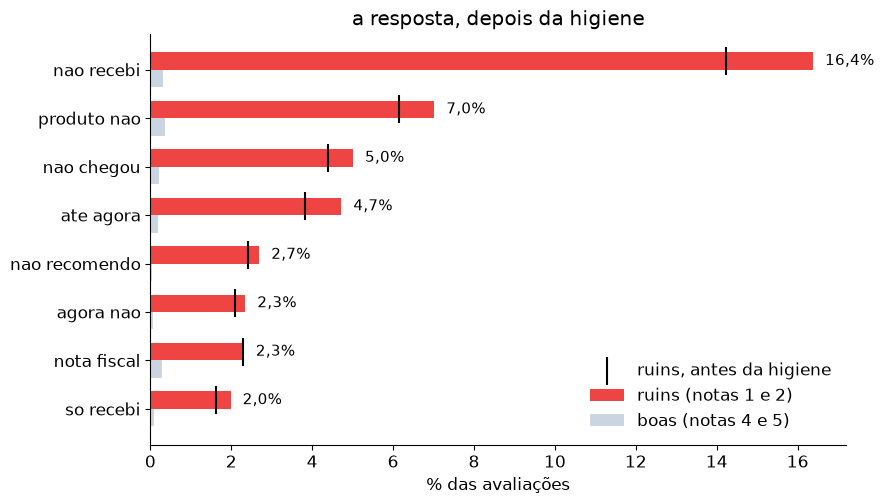

,ruins,boas
bigramas,,
nao recebi,16.4,0.3
produto nao,7.0,0.4
nao chegou,5.0,0.2
ate agora,4.7,0.2
nao recomendo,2.7,0.0
agora nao,2.3,0.1
nota fiscal,2.3,0.3
so recebi,2.0,0.1


In [24]:
# os bigramas no texto bruto e no texto limpo (stopwords normalizadas)
antes = bigramas_das_ruins(mensagens, "mensagem", stop)
depois = bigramas_das_ruins(final, "norm", {normalizar(w) for w in stop})
# os 8 mais citados nas ruins, entre os 8 vezes (ou mais) mais comuns nelas
depois = depois[depois["ruins"] >= 8 * depois["boas"]].head(8)

# para cada bigrama limpo, a grafia mais citada no bruto ("não recebi" para "nao recebi")
antes_limpo = antes["ruins"].groupby(antes.index.map(normalizar)).max()
grafico_ruins_boas(depois.index, depois["ruins"], depois["boas"], "a resposta, depois da higiene",
                   antes=antes_limpo[depois.index])
depois.round(1)


**A ordem não muda: a entrega lidera.** "não recebi" e "nao recebi" viraram um bigrama só, e ele
passou de 14,2% para 16,4% das avaliações ruins. Os grupos de reclamações parecidas confirmam: os
três maiores são de entrega. A higiene não trocou a resposta; tornou a resposta confiável, com
cada cliente contado uma vez e as grafias juntas.